# Chatbot tìm & gợi ý sách bằng **Rasa** (Kaggle)
Hệ thống hội thoại hướng tác vụ theo kiến trúc **pipeline** của Rasa Open Source 3.6, dùng để đối chiếu với cách tiếp cận end-to-end (T5/BART) ở notebook trước.

```
Người dùng ──► [NLU: DIETClassifier]  ──► intent + entity (genre, author, price_max, ...)
                       │
                [Dialogue policies: RulePolicy + TEDPolicy]  ──► chọn action tiếp theo
                       │
          [Custom action server (rasa_sdk)]  ──► truy vấn kho sách ──► câu trả lời
```

| Thành phần | Vai trò trong đề tài |
|---|---|
| `data/nlu.yml` | câu mẫu có gắn nhãn intent/entity (sinh tự động từ kho sách, có biến thể **không dấu**) |
| `data/rules.yml`, `data/stories.yml` | luật & kịch bản hội thoại |
| `domain.yml` | intent, entity, slot, câu trả lời cố định |
| `actions/actions.py` | tìm sách, lọc thêm, hỏi chi tiết ("cuốn thứ hai giá bao nhiêu?"), tìm theo tên |

### ⚠️ Cần biết trước khi chạy
1. **Kaggle:** *Settings → Internet = On*. GPU **không bắt buộc** (Rasa chạy CPU, bản này tắt GPU cho tránh lỗi CUDA/TensorFlow).
2. **Rasa 3.6.21 chỉ chạy trên Python 3.8–3.10**, còn Kaggle dùng Python mới hơn, nên notebook tạo môi trường Python 3.10 riêng bằng `uv` rồi cài Rasa vào đó (mất khoảng 5–10 phút, tải TensorFlow).
3. **Dữ liệu là mô phỏng:** tên sách/tác giả/thể loại/năm lấy từ kiến thức chung về các đầu sách phổ biến (có nhóm truyện tranh, thiếu nhi, kỹ năng sống như trên Fahasa, NXB Kim Đồng); **không** crawl từ website nào. `rating` và `price` là **số ngẫu nhiên** (seed cố định). Cách thay bằng dữ liệu thật: xem biến `CATALOG_CSV` ở mục 1. Câu trả lời viết theo giọng nhân viên nhà sách, do mình tự soạn.
4. Notebook được kiểm thử phần sinh dữ liệu và logic custom action; **phần cài/huấn luyện Rasa chưa được chạy thử** (môi trường soạn thảo không có mạng). Nếu lỗi, gửi lại tên cell và dòng cuối của thông báo.

## 0. Cấu hình & hàm tiện ích

In [1]:
import os, sys, re, json, math, time, random, shutil, subprocess, unicodedata, urllib.request
from pathlib import Path

SEED = 42
random.seed(SEED)

ON_KAGGLE = Path("/kaggle/working").exists()
ROOT = Path("/kaggle/working") if ON_KAGGLE else Path.cwd()   # thư mục này được Kaggle lưu lại làm output
PROJ = ROOT / "book_rasa"                                     # project Rasa
VENV = Path("/tmp/rasa_env")                                  # môi trường Python 3.10 (không cần lưu lại)
RASA = str(VENV / "bin" / "rasa")
for d in ["data", "actions", "tests", "models", "results"]:
    (PROJ / d).mkdir(parents=True, exist_ok=True)


def rasa_env():
    """Môi trường sạch cho tiến trình Rasa: bỏ PYTHONPATH của Kaggle (hay gây xung đột), tắt GPU & telemetry."""
    env = {k: v for k, v in os.environ.items() if k not in ("PYTHONPATH", "PYTHONHOME", "VIRTUAL_ENV")}
    env.update(PYTHONNOUSERSITE="1", RASA_TELEMETRY_ENABLED="false", TF_CPP_MIN_LOG_LEVEL="2",
               CUDA_VISIBLE_DEVICES="", PATH=f"{VENV / 'bin'}:" + os.environ.get("PATH", ""))
    return env


def sh(cmd, cwd=None, env=None, check=True, quiet=False):
    """Chạy lệnh, in output theo thời gian thực; báo lỗi kèm 40 dòng cuối nếu thất bại."""
    p = subprocess.Popen(cmd, cwd=cwd, env=env, shell=isinstance(cmd, str), text=True, bufsize=1,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = []
    for line in p.stdout:
        lines.append(line)
        if not quiet: print(line, end="")
    p.wait()
    if check and p.returncode != 0:
        raise RuntimeError(f"Lệnh lỗi (mã {p.returncode}): {cmd}\n--- 40 dòng cuối ---\n" + "".join(lines[-40:]))
    return "".join(lines)


def fold(s):
    """Bỏ dấu tiếng Việt + chữ thường (dùng để tạo biến thể không dấu)."""
    s = unicodedata.normalize("NFD", str(s).lower().replace("đ", "d"))
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return re.sub(r"\s+", " ", s).strip()

print("Project:", PROJ)

Project: /kaggle/working/book_rasa


## Cài đặt Rasa (môi trường Python 3.10 riêng)

In [2]:
# Chỉ cần chạy 1 lần mỗi phiên (mất ~5-10 phút). Yêu cầu: Settings > Internet = On.
if not (VENV / "bin" / "rasa").exists():
    sh([sys.executable, "-m", "pip", "install", "-q", "uv"])
    sh([sys.executable, "-m", "uv", "python", "install", "3.10"])
    sh([sys.executable, "-m", "uv", "venv", "--python", "3.10", "--seed", str(VENV)])
    try:
        sh([sys.executable, "-m", "uv", "pip", "install", "--python", str(VENV / "bin" / "python"), "rasa==3.6.21"])
    except RuntimeError as e:
        print("[!] uv pip lỗi, thử lại bằng pip trong venv...\n", str(e)[:500])
        sh([str(VENV / "bin" / "python"), "-m", "pip", "install", "rasa==3.6.21"])
print(sh([RASA, "--version"], env=rasa_env(), quiet=True)[-600:])

Installed Python 3.10.22 in 1.09s
 + cpython-3.10.22-linux-x86_64-gnu (python3.10)
Using CPython 3.10.22
Creating virtual environment with seed packages at: /tmp/rasa_env
 + packaging==26.3
 + pip==26.3
 + setuptools==84.2.1
 + wheel==0.48.0
Activate with: source /tmp/rasa_env/bin/activate
Using Python 3.10.22 environment at: /tmp/rasa_env
Resolved 164 packages in 2.70s
Prepared 164 packages in 1m 00s
Uninstalled 3 packages in 8ms
Installed 164 packages in 424ms
 + absl-py==1.4.0
 + aio-pika==8.2.3
 + aiofiles==25.1.0
 + aiogram==2.15
 + aiohttp==3.9.5
 + aiohttp-retry==2.9.1
 + aiormq==6.4.2
 + aiosignal==1.4.0
 + anyio==4.16.0
 + apscheduler==3.9.1.post1
 + astunparse==1.6.3
 + async-timeout==4.0.3
 + attrs==22.1.0
 + babel==2.18.0
 + bidict==0.23.1
 + boto3==1.44.7
 + botocore==1.44.7
 + cachecontrol==0.12.14
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.1
 + cloudpickle==3.1.3
 + colorclass==2.2.2
 + coloredlogs==15.0.1
 + colorhash==1.2.1
 + conf

## 1. Kho sách (Knowledge Base)
Mỗi sách có `title, author, genre, year, rating, price` (giá tính theo **nghìn đồng**). Hãy **thay bằng dữ liệu thật** nếu có: đặt `CATALOG_CSV` trỏ tới file CSV có đủ 6 cột trên (ví dụ file bạn tự thu thập hợp lệ từ nhà sách và upload thành dataset Kaggle). Mọi phần phía sau (câu mẫu NLU, lookup table, action) tự lấy theo kho này.

In [3]:
RAW_BOOKS = [
    # (title, author, genre, year)
    ("Mắt Biếc", "Nguyễn Nhật Ánh", "văn học", 1990),
    ("Tôi Thấy Hoa Vàng Trên Cỏ Xanh", "Nguyễn Nhật Ánh", "văn học", 2010),
    ("Cho Tôi Xin Một Vé Đi Tuổi Thơ", "Nguyễn Nhật Ánh", "thiếu nhi", 2008),
    ("Cô Gái Đến Từ Hôm Qua", "Nguyễn Nhật Ánh", "tình cảm", 1989),
    ("Dế Mèn Phiêu Lưu Ký", "Tô Hoài", "thiếu nhi", 1941),
    ("Số Đỏ", "Vũ Trọng Phụng", "văn học", 1936),
    ("Cánh Đồng Bất Tận", "Nguyễn Ngọc Tư", "văn học", 2005),
    ("Nhà Giả Kim", "Paulo Coelho", "văn học", 1988),
    ("Bố Già", "Mario Puzo", "văn học", 1969),
    ("Rừng Na Uy", "Haruki Murakami", "tình cảm", 1987),
    ("Hai Số Phận", "Jeffrey Archer", "tình cảm", 1979),
    ("Sherlock Holmes Toàn Tập", "Arthur Conan Doyle", "trinh thám", 1892),
    ("Án Mạng Trên Chuyến Tàu Tốc Hành Phương Đông", "Agatha Christie", "trinh thám", 1934),
    ("Và Rồi Chẳng Còn Ai", "Agatha Christie", "trinh thám", 1939),
    ("Mật Mã Da Vinci", "Dan Brown", "trinh thám", 2003),
    ("Nghi Can X", "Higashino Keigo", "trinh thám", 2005),
    ("Bạch Dạ Hành", "Higashino Keigo", "trinh thám", 1999),
    ("Dune", "Frank Herbert", "khoa học viễn tưởng", 1965),
    ("1984", "George Orwell", "khoa học viễn tưởng", 1949),
    ("Hai Vạn Dặm Dưới Đáy Biển", "Jules Verne", "khoa học viễn tưởng", 1870),
    ("Ender Trò Chơi Chiến Tranh", "Orson Scott Card", "khoa học viễn tưởng", 1985),
    ("Tam Thể", "Lưu Từ Hân", "khoa học viễn tưởng", 2008),
    ("Cha Giàu Cha Nghèo", "Robert Kiyosaki", "kinh tế", 1997),
    ("Tư Duy Nhanh Và Chậm", "Daniel Kahneman", "kinh tế", 2011),
    ("Nghĩ Giàu Làm Giàu", "Napoleon Hill", "kinh tế", 1937),
    ("Người Giàu Có Nhất Thành Babylon", "George Clason", "kinh tế", 1926),
    ("Khởi Nghiệp Tinh Gọn", "Eric Ries", "kinh tế", 2011),
    ("Đắc Nhân Tâm", "Dale Carnegie", "tâm lý", 1936),
    ("Nghệ Thuật Tinh Tế Của Việc Đếch Quan Tâm", "Mark Manson", "tâm lý", 2016),
    ("Sức Mạnh Của Thói Quen", "Charles Duhigg", "tâm lý", 2012),
    ("Dám Bị Ghét", "Kishimi Ichiro", "tâm lý", 2013),
    ("Phi Lý Trí", "Dan Ariely", "tâm lý", 2008),
    ("Hiểu Về Trái Tim", "Minh Niệm", "tâm lý", 2011),
    ("Sapiens Lược Sử Loài Người", "Yuval Noah Harari", "lịch sử", 2011),
    ("Súng Vi Trùng Và Thép", "Jared Diamond", "lịch sử", 1997),
    ("Việt Nam Sử Lược", "Trần Trọng Kim", "lịch sử", 1920),
    ("Lược Sử Thời Gian", "Stephen Hawking", "khoa học", 1988),
    ("Vũ Trụ Trong Vỏ Hạt Dẻ", "Stephen Hawking", "khoa học", 2001),
    ("Cosmos", "Carl Sagan", "khoa học", 1980),
    ("Hoàng Tử Bé", "Antoine de Saint-Exupéry", "thiếu nhi", 1943),
    ("Harry Potter Và Hòn Đá Phù Thủy", "J.K. Rowling", "thiếu nhi", 1997),
    ("Totto-chan Bên Cửa Sổ", "Tetsuko Kuroyanagi", "thiếu nhi", 1981),
    ("Clean Code", "Robert C. Martin", "công nghệ", 2008),
    ("The Pragmatic Programmer", "Andrew Hunt", "công nghệ", 1999),
    ("Introduction To Algorithms", "Thomas Cormen", "công nghệ", 1990),
    ("Deep Learning", "Ian Goodfellow", "công nghệ", 2016),
    ("Designing Data-Intensive Applications", "Martin Kleppmann", "công nghệ", 2017),
    ("Don't Make Me Think", "Steve Krug", "công nghệ", 2000),
    ("The Design Of Everyday Things", "Don Norman", "công nghệ", 1988),
    # --- thêm: truyện tranh / thiếu nhi / kỹ năng sống (kiểu danh mục Fahasa, NXB Kim Đồng) ---
    ("Doraemon", "Fujiko F. Fujio", "truyện tranh", 1969),
    ("Thám Tử Lừng Danh Conan", "Aoyama Gosho", "truyện tranh", 1994),
    ("Dragon Ball", "Akira Toriyama", "truyện tranh", 1984),
    ("Naruto", "Masashi Kishimoto", "truyện tranh", 1999),
    ("One Piece", "Eiichiro Oda", "truyện tranh", 1997),
    ("Kính Vạn Hoa", "Nguyễn Nhật Ánh", "thiếu nhi", 1995),
    ("Nhóc Nicolas", "René Goscinny", "thiếu nhi", 1959),
    ("Truyện Cổ Andersen", "Hans Christian Andersen", "thiếu nhi", 1835),
    ("Truyện Cổ Grimm", "Anh Em Grimm", "thiếu nhi", 1812),
    ("Cây Cam Ngọt Của Tôi", "José Mauro de Vasconcelos", "văn học", 1968),
    ("Những Người Khốn Khổ", "Victor Hugo", "văn học", 1862),
    ("Lão Hạc", "Nam Cao", "văn học", 1943),
    ("Tuổi Trẻ Đáng Giá Bao Nhiêu", "Rosie Nguyễn", "kỹ năng sống", 2016),
    ("7 Thói Quen Của Người Thành Đạt", "Stephen R. Covey", "kỹ năng sống", 1989),
    ("Atomic Habits", "James Clear", "kỹ năng sống", 2018),
    ("Deep Work", "Cal Newport", "kỹ năng sống", 2016),
]

CATALOG_CSV = None     # ví dụ: "/kaggle/input/my-books/books.csv"  (cột: title,author,genre,year,rating,price)

# Cách người dùng hay gọi tên thể loại (dùng cho câu mẫu NLU và để chuẩn hoá trong action)
GENRE_ALIASES = {
    "trinh thám": ["trinh thám", "truyện trinh thám"],
    "khoa học viễn tưởng": ["khoa học viễn tưởng", "viễn tưởng", "sci-fi"],
    "tâm lý": ["tâm lý", "tâm lý học"],
    "kinh tế": ["kinh tế", "kinh doanh"],
    "văn học": ["văn học", "tiểu thuyết"],
    "thiếu nhi": ["thiếu nhi", "truyện thiếu nhi", "sách cho bé"],
    "truyện tranh": ["truyện tranh", "manga", "comic"],
    "công nghệ": ["công nghệ", "lập trình"],
    "tình cảm": ["tình cảm", "ngôn tình"],
    "kỹ năng sống": ["kỹ năng sống", "phát triển bản thân"],
    "lịch sử": ["lịch sử"],
    "khoa học": ["khoa học"],
}

if CATALOG_CSV:
    import csv
    with open(CATALOG_CSV, encoding="utf-8-sig") as f:
        BOOKS = [dict(id=i, title=r["title"].strip(), author=r["author"].strip(), genre=r["genre"].strip().lower(),
                      year=int(r["year"]), rating=round(float(r["rating"]), 1), price=int(float(r["price"])))
                 for i, r in enumerate(csv.DictReader(f))]
else:
    _rng = random.Random(0)
    BOOKS = [dict(id=i, title=t, author=a, genre=g, year=y,
                  rating=round(_rng.uniform(3.8, 4.8), 1),      # MÔ PHỎNG
                  price=_rng.randrange(40, 260, 5))             # MÔ PHỎNG (nghìn đồng)
             for i, (t, a, g, y) in enumerate(RAW_BOOKS)]

GENRES  = sorted({b["genre"] for b in BOOKS})
AUTHORS = sorted({b["author"] for b in BOOKS})
TITLES  = [b["title"] for b in BOOKS]
GENRE_ALIASES = {g: GENRE_ALIASES.get(g, [g]) for g in GENRES}

(PROJ / "data" / "books.json").write_text(json.dumps(BOOKS, ensure_ascii=False, indent=1), encoding="utf-8")
(PROJ / "data" / "genre_aliases.json").write_text(json.dumps(GENRE_ALIASES, ensure_ascii=False, indent=1), encoding="utf-8")
print(len(BOOKS), "cuốn |", len(GENRES), "thể loại:", ", ".join(GENRES))
print(BOOKS[0])

65 cuốn | 12 thể loại: công nghệ, khoa học, khoa học viễn tưởng, kinh tế, kỹ năng sống, lịch sử, thiếu nhi, trinh thám, truyện tranh, tâm lý, tình cảm, văn học
{'id': 0, 'title': 'Mắt Biếc', 'author': 'Nguyễn Nhật Ánh', 'genre': 'văn học', 'year': 1990, 'rating': 4.6, 'price': 170}


## 2. Cấu hình Rasa
* **NLU:** `WhitespaceTokenizer` (tiếng Việt tách theo âm tiết bằng khoảng trắng) + `CountVectorsFeaturizer` mức từ và mức ký tự (n-gram ký tự giúp chịu lỗi gõ sai/không dấu) → `DIETClassifier` (intent + entity cùng lúc) → `FallbackClassifier`.
* **Policies:** `MemoizationPolicy`, `RulePolicy`, `TEDPolicy`.

In [4]:
CONFIG_YML = r"""
recipe: default.v1
language: vi
assistant_id: book-rasa-bot

pipeline:
  - name: WhitespaceTokenizer
  - name: RegexFeaturizer
  - name: LexicalSyntacticFeaturizer
  - name: CountVectorsFeaturizer
  - name: CountVectorsFeaturizer
    analyzer: char_wb
    min_ngram: 1
    max_ngram: 4
  - name: DIETClassifier
    epochs: 80
    constrain_similarities: true
  - name: EntitySynonymMapper
  - name: FallbackClassifier
    threshold: 0.4
    ambiguity_threshold: 0.1

policies:
  - name: MemoizationPolicy
  - name: RulePolicy
  - name: TEDPolicy
    max_history: 5
    epochs: 50
    constrain_similarities: true
"""

ENDPOINTS_YML = r"""
action_endpoint:
  url: "http://localhost:5055/webhook"
"""

CREDENTIALS_YML = r"""
rest:
"""

for name, txt in [("config.yml", CONFIG_YML), ("endpoints.yml", ENDPOINTS_YML), ("credentials.yml", CREDENTIALS_YML)]:
    (PROJ / name).write_text(txt.strip() + "\n", encoding="utf-8")
print("Đã ghi config.yml, endpoints.yml, credentials.yml")

Đã ghi config.yml, endpoints.yml, credentials.yml


## 3. Custom actions (logic nghiệp vụ)
Action server là nơi truy vấn kho sách. Điểm đáng chú ý:
* Đọc entity do NLU trích xuất; nếu NLU bỏ sót thì **dự phòng bằng regex/so khớp chuỗi** (giá `dưới 150k`, `đánh giá từ 4.0 sao`, tên thể loại/tác giả/tên sách, `cuốn thứ hai`...) nên chatbot ít vỡ khi NLU sai.
* So khớp **không phân biệt dấu** (`trinh tham` = `trinh thám`) và có **fuzzy matching** cho tên sách/tác giả.
* `search_book` = tìm mới (xoá điều kiện cũ), `refine_search` = **lọc thêm** (giữ điều kiện cũ).
* Slot `result_ids` nhớ danh sách vừa gợi ý để hiểu "cuốn thứ hai", "cuốn này".

In [5]:
ACTIONS_PY = r"""
import json
import re
import difflib
import unicodedata
from pathlib import Path
from typing import Any, Dict, List, Text

from rasa_sdk import Action, Tracker
from rasa_sdk.events import SlotSet
from rasa_sdk.executor import CollectingDispatcher

DATA = Path(__file__).resolve().parent.parent / "data"
BOOKS = json.loads((DATA / "books.json").read_text(encoding="utf-8"))
ALIASES = json.loads((DATA / "genre_aliases.json").read_text(encoding="utf-8"))
BY_ID = {b["id"]: b for b in BOOKS}
FILTERS = ["genre", "author", "rating_min", "price_max", "year_min"]


def fold(s):
    s = unicodedata.normalize("NFD", str(s).lower().replace("đ", "d"))
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return re.sub(r"\s+", " ", s).strip()


def has(pattern, text):
    return re.search(pattern, text) is not None


GENRES = sorted({b["genre"] for b in BOOKS})
GENRE_LOOKUP = {fold(g): g for g in GENRES}
for _g, _al in ALIASES.items():
    for _a in _al:
        GENRE_LOOKUP[fold(_a)] = _g
GENRE_KEYS = sorted(GENRE_LOOKUP, key=len, reverse=True)          # ưu tiên cụm dài nhất
AUTHOR_FOLD = {fold(a): a for a in sorted({b["author"] for b in BOOKS})}
TITLE_FOLD = {fold(b["title"]): b for b in BOOKS}


def bounded(key, text):
    return has(r"(?<!\w)" + re.escape(key) + r"(?!\w)", text)


# ---------------- chuẩn hoá giá trị ----------------
def canon_genre(v):
    f = fold(v)
    if not f:
        return None
    if f in GENRE_LOOKUP:
        return GENRE_LOOKUP[f]
    for k in GENRE_KEYS:
        if bounded(k, f):
            return GENRE_LOOKUP[k]
    m = difflib.get_close_matches(f, GENRE_KEYS, n=1, cutoff=0.8)
    return GENRE_LOOKUP[m[0]] if m else None


def canon_author(v):
    f = fold(v)
    if len(f) < 3:
        return None
    if f in AUTHOR_FOLD:
        return AUTHOR_FOLD[f]
    part = [a for k, a in AUTHOR_FOLD.items() if f in k or (len(k) >= 4 and k in f)]
    if part:
        return part[0]
    m = difflib.get_close_matches(f, list(AUTHOR_FOLD), n=1, cutoff=0.75)
    return AUTHOR_FOLD[m[0]] if m else None


def to_number(s):
    m = re.search(r"\d[\d.,]*", fold(s))
    if not m:
        return None
    raw = m.group(0).rstrip(".,")
    if re.fullmatch(r"\d{1,3}([.,]\d{3})+", raw):
        raw = re.sub(r"[.,]", "", raw)
    else:
        raw = raw.replace(",", ".")
    try:
        return float(raw)
    except ValueError:
        return None


def norm_price(s):
    v = to_number(s)
    if v is None:
        return None
    return int(round(v / 1000 if v >= 1000 else v))


def norm_rating(s):
    v = to_number(s)
    return round(v, 1) if v is not None and 1 <= v <= 5 else None


def norm_year(s):
    v = to_number(s)
    return int(v) if v is not None and 1000 <= v <= 2100 else None


def parse_constraints(text):
    # dự phòng khi NLU không trích được entity số
    f = fold(text)
    out = {}
    m = re.search(r"(?:duoi|khong qua|toi da|re hon|nho hon)\s*(\d[\d.,]*)", f)
    if m:
        out["price_max"] = norm_price(m.group(1))
    m = re.search(r"(?:danh gia|rating|diem)\D{0,12}?(\d(?:[.,]\d)?)(?!\d)", f) or re.search(r"(\d(?:[.,]\d)?)\s*sao", f)
    if m:
        out["rating_min"] = norm_rating(m.group(1))
    m = re.search(r"(?:sau|tu|moi hon)\s*nam\s*(\d{4})", f)
    if m:
        out["year_min"] = norm_year(m.group(1))
    return {k: v for k, v in out.items() if v is not None}


ORD_PATTERNS = [
    (1, r"dau tien|thu nhat|(?:thu|so|cuon|quyen)\s*1\b|cuon dau|quyen dau|\bdau\b"),
    (2, r"thu hai|(?:thu|so)\s*2\b|cuon hai|quyen hai"),
    (3, r"thu ba|(?:thu|so)\s*3\b|cuon ba|quyen ba"),
    (4, r"thu bon|thu tu|(?:thu|so)\s*4\b"),
    (5, r"thu nam|(?:thu|so)\s*5\b"),
]
ASK_PATTERNS = [
    ("author", r"tac gia|ai viet|ai sang tac|ai la tac|cua ai"),
    ("year", r"nam nao|nam xuat ban|xuat ban nam|xuat ban khi|ra mat|phat hanh"),
    ("genre", r"the loai|thuoc loai|loai gi|chu de"),
    ("rating", r"danh gia|\bsao\b|diem|hay khong|co hay|review"),
    ("price", r"\bgia\b|tien|bao nhieu"),
]


def parse_ordinal(*texts):
    for t in texts:
        f = fold(t or "")
        for n, pat in ORD_PATTERNS:
            if has(pat, f):
                return n
    return None


def parse_ask(*texts):
    for t in texts:
        f = fold(t or "")
        for name, pat in ASK_PATTERNS:
            if has(pat, f):
                return name
    return None


# ---------------- truy vấn & định dạng ----------------
def search(state):
    rows = BOOKS
    if state.get("genre"):
        rows = [b for b in rows if b["genre"] == state["genre"]]
    if state.get("author"):
        rows = [b for b in rows if b["author"] == state["author"]]
    if state.get("rating_min") not in (None, ""):
        rows = [b for b in rows if b["rating"] >= float(state["rating_min"])]
    if state.get("price_max") not in (None, ""):
        rows = [b for b in rows if b["price"] <= float(state["price_max"])]
    if state.get("year_min") not in (None, ""):
        rows = [b for b in rows if b["year"] >= int(float(state["year_min"]))]
    return sorted(rows, key=lambda b: (-b["rating"], b["id"]))


def money(p):
    return f"{int(p) * 1000:,}".replace(",", ".") + "đ"


def describe(state):
    parts = []
    if state.get("genre"):
        parts.append(f"thể loại {state['genre']}")
    if state.get("author"):
        parts.append(f"của tác giả {state['author']}")
    if state.get("rating_min") not in (None, ""):
        parts.append(f"đánh giá từ {float(state['rating_min']):.1f}★ trở lên")
    if state.get("price_max") not in (None, ""):
        parts.append(f"giá dưới {money(state['price_max'])}")
    if state.get("year_min") not in (None, ""):
        parts.append(f"xuất bản từ năm {int(float(state['year_min']))}")
    return ", ".join(parts)


def line(i, b):
    return f"{i}. {b['title']} – {b['author']} | {b['year']} | {b['rating']:.1f}★ | {money(b['price'])}"


def card(b):
    return (f"Cuốn {b['title']}:\n- Tác giả: {b['author']}\n- Thể loại: {b['genre']}\n"
            f"- Năm xuất bản: {b['year']}\n- Đánh giá: {b['rating']:.1f}/5★\n- Giá: {money(b['price'])}")


def entities(tracker):
    out = {}
    for e in tracker.latest_message.get("entities", []) or []:
        out.setdefault(e.get("entity"), e.get("value"))
    return out


def latest_text(tracker):
    return tracker.latest_message.get("text") or ""


def reset_filters():
    return [SlotSet(k, None) for k in FILTERS]


# ---------------- Actions ----------------
class ActionSearchBooks(Action):
    def name(self) -> Text:
        return "action_search_books"

    def run(self, dispatcher: CollectingDispatcher, tracker: Tracker, domain: Dict[Text, Any]) -> List[Dict[Text, Any]]:
        intent = (tracker.latest_message.get("intent") or {}).get("name")
        text = latest_text(tracker)
        f = fold(text)
        ents = entities(tracker)

        new, unknown = {}, None
        # thể loại: entity -> dự phòng quét văn bản
        if ents.get("genre"):
            g = canon_genre(ents["genre"])
            if g:
                new["genre"] = g
            else:
                unknown = ents["genre"]
        else:
            for k in GENRE_KEYS:
                if bounded(k, f):
                    new["genre"] = GENRE_LOOKUP[k]
                    break
        # tác giả
        if ents.get("author"):
            a = canon_author(ents["author"])
            if a:
                new["author"] = a
        else:
            for k, a in AUTHOR_FOLD.items():
                if len(k) >= 4 and bounded(k, f):
                    new["author"] = a
                    break
        # số liệu: entity -> dự phòng regex
        rx = parse_constraints(text)
        for slot, fn in [("rating_min", norm_rating), ("price_max", norm_price), ("year_min", norm_year)]:
            v = fn(ents[slot]) if ents.get(slot) else None
            if v is None:
                v = rx.get(slot)
            if v is not None:
                new[slot] = v

        state = {k: tracker.get_slot(k) for k in FILTERS} if intent == "refine_search" else {}
        state.update({k: v for k, v in new.items() if v not in (None, "")})
        events = [SlotSet(k, None if state.get(k) in (None, "") else str(state[k])) for k in FILTERS]
        events.append(SlotSet("title", None))

        if unknown and not state:
            dispatcher.utter_message(text=f"Dạ hiện nhà sách chưa có thể loại \"{unknown}\". Các thể loại đang có: "
                                          + ", ".join(GENRES) + ". Bạn muốn xem thể loại nào ạ?")
            return events + [SlotSet("result_ids", [])]
        if not state:
            dispatcher.utter_message(text="Dạ bạn muốn tìm sách thể loại nào ạ? Hiện có: " + ", ".join(GENRES)
                                          + ". Bạn cũng có thể nói tên tác giả hoặc tên sách.")
            return events + [SlotSet("result_ids", [])]

        rows = search(state)
        desc = describe(state)
        if not rows:
            dispatcher.utter_message(text=f"Dạ rất tiếc, hiện chưa có cuốn nào phù hợp với yêu cầu ({desc}). "
                                          "Bạn thử nới lỏng điều kiện (giá, đánh giá) hoặc chọn thể loại khác nhé ạ.")
            return events + [SlotSet("result_ids", [])]

        top = rows[:5]
        msg = f"Dạ, mình tìm được {len(rows)} cuốn phù hợp ({desc}). Top gợi ý:\n" + "\n".join(line(i, b) for i, b in enumerate(top, 1))
        msg += "\nBạn muốn xem chi tiết cuốn nào, hay lọc thêm theo giá, đánh giá, năm xuất bản ạ?"
        buttons = [{"title": "Xem chi tiết cuốn đầu tiên", "payload": "Cho mình xem chi tiết cuốn đầu tiên"},
                   {"title": "Đánh giá từ 4.5 sao", "payload": "Lọc thêm giúp mình đánh giá từ 4.5 sao trở lên"},
                   {"title": "Giá dưới 150k", "payload": "Lọc thêm giúp mình giá dưới 150k"}]
        dispatcher.utter_message(text=msg, buttons=buttons)
        return events + [SlotSet("result_ids", [b["id"] for b in top])]


class ActionBookDetail(Action):
    def name(self) -> Text:
        return "action_book_detail"

    def run(self, dispatcher: CollectingDispatcher, tracker: Tracker, domain: Dict[Text, Any]) -> List[Dict[Text, Any]]:
        ids = tracker.get_slot("result_ids") or []
        ents = entities(tracker)
        text = latest_text(tracker)
        if not ids:
            dispatcher.utter_message(text="Dạ mình chưa có danh sách nào để tra cứu. Bạn cho mình biết thể loại hoặc tên sách bạn quan tâm nhé ạ.")
            return []
        idx = parse_ordinal(ents.get("ordinal"), text)
        if idx is None:
            if len(ids) == 1:
                idx = 1
            else:
                dispatcher.utter_message(text="Dạ bạn muốn xem cuốn nào trong danh sách ạ? Ví dụ: cuốn thứ hai.")
                return []
        if idx > len(ids):
            dispatcher.utter_message(text=f"Dạ danh sách hiện chỉ có {len(ids)} cuốn thôi ạ.")
            return []
        b = BY_ID[int(ids[idx - 1])]
        ask = parse_ask(ents.get("ask"), text)
        answers = {
            "price": f"Dạ, cuốn {b['title']} có giá {money(b['price'])}.",
            "author": f"Dạ, {b['title']} là sáng tác của {b['author']} ạ.",
            "rating": f"Dạ, {b['title']} được đánh giá {b['rating']:.1f}/5 sao ạ.",
            "year": f"Dạ, {b['title']} xuất bản năm {b['year']} ạ.",
            "genre": f"Dạ, {b['title']} thuộc thể loại {b['genre']} ạ.",
        }
        dispatcher.utter_message(text=answers[ask] if ask in answers else "Dạ, thông tin chi tiết ạ:\n" + card(b))
        return []


class ActionSearchTitle(Action):
    def name(self) -> Text:
        return "action_search_title"

    def run(self, dispatcher: CollectingDispatcher, tracker: Tracker, domain: Dict[Text, Any]) -> List[Dict[Text, Any]]:
        f = fold(latest_text(tracker))
        ent = entities(tracker).get("title")
        hits = [t for t in TITLE_FOLD if bounded(t, f)]
        found = [TITLE_FOLD[max(hits, key=len)]] if hits else []
        if not found and ent and len(fold(ent)) >= 3:
            q = fold(ent)
            sub = [TITLE_FOLD[t] for t in TITLE_FOLD if q in t]
            if sub:
                found = sub[:5]
            else:
                m = difflib.get_close_matches(q, list(TITLE_FOLD), n=1, cutoff=0.75)
                found = [TITLE_FOLD[m[0]]] if m else []
        events = reset_filters() + [SlotSet("title", ent)]
        if not found:
            label = f" \"{ent}\"" if ent else ""
            dispatcher.utter_message(text=f"Dạ rất tiếc, mình chưa tìm thấy cuốn{label} trong kho. Bạn kiểm tra lại tên sách "
                                          "hoặc để mình gợi ý theo thể loại, tác giả nhé ạ.")
            return events + [SlotSet("result_ids", [])]
        if len(found) == 1:
            dispatcher.utter_message(text="Dạ có ạ! " + card(found[0]) + "\nBạn cần mình gợi ý thêm sách tương tự không ạ?")
        else:
            dispatcher.utter_message(text="Dạ mình tìm thấy các cuốn gần với yêu cầu của bạn:\n"
                                          + "\n".join(line(i, b) for i, b in enumerate(found, 1))
                                          + "\nBạn muốn xem chi tiết cuốn nào ạ?")
        return events + [SlotSet("result_ids", [b["id"] for b in found])]
"""

(PROJ / "actions" / "__init__.py").write_text("", encoding="utf-8")
(PROJ / "actions" / "actions.py").write_text(ACTIONS_PY.strip() + "\n", encoding="utf-8")
print("Đã ghi actions/actions.py")

Đã ghi actions/actions.py


## 4. Dữ liệu NLU (sinh tự động từ kho sách)
Gồm các intent: `search_book`, `refine_search`, `ask_detail`, `search_by_title`, và các intent xã giao (`greet`, `goodbye`, `thank`, `affirm`, `deny`, `bot_challenge`, `ask_capability`, `out_of_domain`).
* Entity: `genre, author, rating_min, price_max, year_min, title, ask, ordinal`.
* Khoảng **15% câu có thêm biến thể không dấu** ("goi y sach trinh tham") vì người dùng thật hay gõ vậy.
* **Lookup table** cho thể loại/tác giả/tên sách giúp DIET nhận diện entity tốt hơn.

> Vì câu mẫu sinh từ template nên điểm đánh giá NLU sẽ rất cao; hãy bổ sung câu thật (từ bạn bè, khảo sát) vào `data/nlu.yml` để số liệu đáng tin hơn.

In [6]:
rng = random.Random(SEED)

def E(text, ent):                       # gắn nhãn entity theo cú pháp Rasa: [văn bản](entity)
    return f"[{text}]({ent})"

def cap(s):
    return s[:1].upper() + s[1:]

# ---------- các cụm điều kiện ----------
def genre_clause():
    g = E(rng.choice(GENRE_ALIASES[rng.choice(GENRES)]), "genre")
    return rng.choice(["sách {v}", "thể loại {v}", "truyện {v}", "về chủ đề {v}"]).format(v=g)

def author_clause():
    return rng.choice(["của tác giả {v}", "của {v}", "do {v} viết"]).format(v=E(rng.choice(AUTHORS), "author"))

def rating_clause():
    v = E(rng.choice(["3.5", "4.0", "4.2", "4.5", "4.8"]), "rating_min")
    return rng.choice([f"đánh giá từ {v} sao trở lên", f"rating trên {v}", f"điểm đánh giá ít nhất {v} sao"])

def price_clause():
    v = rng.choice([50, 80, 100, 120, 150, 200, 250])
    lead = rng.choice(["giá dưới", "không quá", "giá tối đa", "tầm giá dưới"])
    return f"{lead} {E(str(v) + 'k', 'price_max')}" if rng.random() < .5 else f"{lead} {E(str(v), 'price_max')} nghìn"

def year_clause():
    v = E(str(rng.choice([1990, 2000, 2005, 2010, 2015, 2018, 2020])), "year_min")
    return rng.choice([f"xuất bản sau năm {v}", f"ra mắt từ năm {v}"])

# ---------- search_book ----------
SEARCH_STARTS = [("Gợi ý cho mình", ["", " nhé", " với"]), ("Mình muốn tìm", ["", " ạ", " nhé"]),
                 ("Tìm giúp mình", ["", " với"]), ("Shop có", [" không?", " không ạ", " không bạn?"]),
                 ("Tư vấn giúp mình vài cuốn", ["", " nhé"]), ("Cho mình xem", ["", " với"]),
                 ("Mình đang cần mua", ["", " nhé"]), ("Nhà sách còn", [" không?", " không ạ"])]

def make_search():
    pre, sufs = rng.choice(SEARCH_STARTS)
    r = rng.random()
    clauses = [genre_clause()] if r < .55 else ([author_clause()] if r < .8 else [genre_clause(), author_clause()])
    extras = [f for f in (rating_clause, price_clause, year_clause) if rng.random() < .25][:2]
    rng.shuffle(extras)
    clauses += [f() for f in extras]
    return f"{pre} {' '.join(clauses)}{rng.choice(sufs)}"

# ---------- refine_search ----------
def make_refine():
    pre = rng.choice(["Lọc thêm giúp mình", "Thu hẹp lại,", "Ok, thêm điều kiện", "Cho mình xem loại", "Mình muốn",
                      "Lọc giúp mình", "Chỉ lấy cuốn"])
    clause = rng.choice([price_clause, rating_clause, year_clause, author_clause, price_clause, rating_clause])()
    return f"{pre} {clause}"

# ---------- ask_detail ----------
ORD_FORMS = ["đầu tiên", "thứ nhất", "thứ hai", "thứ ba", "thứ 2", "thứ 3", "số 1", "số 2", "số 3"]
ASK_Q = {"price": ["giá bao nhiêu", "bao nhiêu tiền", "giá thế nào"],
         "author": ["ai viết", "của tác giả nào", "tác giả là ai"],
         "rating": ["được đánh giá thế nào", "được mấy sao", "có hay không"],
         "year": ["xuất bản năm nào", "ra mắt khi nào"],
         "genre": ["thuộc thể loại gì", "là thể loại nào"]}
ASK_N = {"price": "giá", "author": "tác giả", "rating": "đánh giá", "year": "năm xuất bản", "genre": "thể loại"}

def book_ref():
    if rng.random() < .3:
        return rng.choice(["cuốn này", "cuốn đó", "quyển này", "cuốn vừa rồi"])
    return f"{rng.choice(['cuốn', 'quyển'])} {E(rng.choice(ORD_FORMS), 'ordinal')}"

def make_detail():
    a = rng.choice(list(ASK_Q))
    r = rng.random()
    if r < .6:
        return f"{cap(book_ref())} {E(rng.choice(ASK_Q[a]), 'ask')}{rng.choice(['?', '', ' vậy?', ' bạn?'])}"
    if r < .9:
        return f"{rng.choice(['Cho mình biết', 'Cho mình hỏi', 'Mình muốn biết'])} {E(ASK_N[a], 'ask')} của {book_ref()}"
    return f"{rng.choice(['Cho mình xem chi tiết', 'Xem thông tin', 'Cho mình xem thêm về'])} {book_ref()}"

# ---------- search_by_title ----------
TITLE_TPL = ["Shop có cuốn {t} không?", "Tìm giúp mình cuốn {t}", "Cho mình xem thông tin cuốn {t}", "Cuốn {t} thế nào?",
             "Mình muốn mua {t}", "Bạn có sách {t} không?", "{t} giá bao nhiêu vậy?", "Cho mình hỏi về cuốn {t}"]

def make_title():
    t = rng.choice(TITLES)
    t = t if rng.random() < .7 else t.lower()
    return rng.choice(TITLE_TPL).format(t=E(t, "title"))

def gen_unique(fn, n, tries=30000):
    out, seen = [], set()
    for _ in range(tries):
        s = fn()
        if s not in seen:
            seen.add(s); out.append(s)
            if len(out) >= n: break
    return out

# ---------- các intent ngắn viết tay ----------
HAND = {
    "greet": ["Xin chào", "Chào shop", "Hello", "Hi", "Alo", "Chào bạn", "Shop ơi", "Cho mình hỏi chút", "Chào buổi sáng",
              "Hi bạn", "Chào nhà sách", "Bạn ơi", "Xin chào, mình cần tìm sách", "Chào bạn, cho mình hỏi chút nhé"],
    "goodbye": ["Tạm biệt", "Bye", "Hẹn gặp lại", "Thôi mình đi đây", "Mình thoát nhé", "Chào nhé", "Hẹn gặp lại bạn",
                "Vậy là đủ rồi, tạm biệt", "Bye bạn", "Mình đi đây"],
    "thank": ["Cảm ơn bạn", "Cảm ơn shop nhiều", "Thanks", "Cảm ơn nhé", "Mình cảm ơn", "Ok cảm ơn", "Cảm ơn bạn đã tư vấn",
              "Tuyệt vời, cảm ơn", "Cảm ơn nhiều nha", "Thank you"],
    "affirm": ["Đúng rồi", "Ok", "Được", "Vâng", "Dạ", "Đồng ý", "Ừ", "Chính xác", "Ok bạn", "Đúng vậy", "Có"],
    "deny": ["Không", "Không cần đâu", "Thôi", "Không phải", "Chưa đúng", "Không cần nữa", "Không ạ", "Chưa cần"],
    "bot_challenge": ["Bạn là người hay máy?", "Bạn có phải robot không?", "Mình đang nói chuyện với bot à?", "Bạn là AI à?",
                      "Bạn là chatbot đúng không?", "Mình đang chat với người thật hả?"],
    "ask_capability": ["Bạn làm được những gì?", "Bạn giúp được gì cho mình?", "Bạn hỗ trợ gì vậy?", "Chức năng của bạn là gì?",
                       "Hướng dẫn mình cách dùng với", "Bạn có thể giúp gì?", "Mình có thể hỏi bạn những gì?"],
    "out_of_domain": ["Hôm nay thời tiết thế nào?", "Kể mình nghe chuyện cười đi", "Tỷ số trận Việt Nam hôm qua?",
                      "Phí ship về Hà Nội bao nhiêu?", "Đơn hàng của mình bao giờ giao?", "Mình muốn đổi trả hàng",
                      "Giá vàng hôm nay", "Bạn biết nấu phở không?", "Cách đặt vé máy bay", "Shop mở cửa mấy giờ?",
                      "Địa chỉ cửa hàng ở đâu?", "Có mã giảm giá không?", "Mình muốn khiếu nại đơn hàng", "Bạn bao nhiêu tuổi?",
                      "Hôm nay ăn gì ngon?", "Giải thích giúp mình bài toán này", "Dịch giúp mình câu tiếng Anh"],
}

def expand_hand(phrases):
    out = set(phrases)
    for p in phrases:
        out.add(p.lower()); out.add(fold(p))
        if not p.endswith(("?", "!", ".")): out.add(p + " ạ"); out.add(p + " nhé")
    return sorted(out)

def with_folded(exs, p=0.15):
    extra = [fold(e) for e in exs if rng.random() < p]
    return list(dict.fromkeys(exs + [x for x in extra if x not in exs]))

NLU = {
    "search_book":     with_folded(gen_unique(make_search, 380)),
    "refine_search":   with_folded(gen_unique(make_refine, 160)),
    "ask_detail":      with_folded(gen_unique(make_detail, 200)),
    "search_by_title": with_folded(gen_unique(make_title, 170)),
}
for intent, ph in HAND.items():
    NLU[intent] = expand_hand(ph)

def nlu_yaml():
    out = ['version: "3.1"', "nlu:"]
    for intent, exs in NLU.items():
        out.append(f"- intent: {intent}\n  examples: |")
        out += [f"    - {e}" for e in exs]
    lookups = {"genre": sorted({a for al in GENRE_ALIASES.values() for a in al}), "author": AUTHORS, "title": TITLES}
    for name, vals in lookups.items():
        out.append(f"- lookup: {name}\n  examples: |")
        out += [f"    - {v}" for v in vals]
    return "\n".join(out) + "\n"

(PROJ / "data" / "nlu.yml").write_text(nlu_yaml(), encoding="utf-8")
print({k: len(v) for k, v in NLU.items()}, "| tổng:", sum(map(len, NLU.values())), "câu")
for k in ["search_book", "refine_search", "ask_detail", "search_by_title"]:
    print(f"  {k:16s}", NLU[k][0])

{'search_book': 427, 'refine_search': 180, 'ask_detail': 223, 'search_by_title': 197, 'greet': 67, 'goodbye': 49, 'thank': 48, 'affirm': 54, 'deny': 39, 'bot_challenge': 18, 'ask_capability': 23, 'out_of_domain': 65} | tổng: 1390 câu
  search_book      Mình muốn tìm thể loại [kỹ năng sống](genre) tầm giá dưới [150k](price_max) đánh giá từ [3.5](rating_min) sao trở lên
  refine_search    Ok, thêm điều kiện của [Jeffrey Archer](author)
  ask_detail       Mình muốn biết [giá](ask) của quyển [số 3](ordinal)
  search_by_title  [cosmos](title) giá bao nhiêu vậy?


## 5. Domain, rules, stories
Các slot đều do action ghi (`type: custom`) và `influence_conversation: false` nên không ảnh hưởng việc chọn action, giúp stories gọn và ít lỗi.

In [7]:
DOMAIN_YML = r"""
version: "3.1"

intents:
  - greet
  - goodbye
  - thank
  - affirm
  - deny
  - bot_challenge
  - ask_capability
  - out_of_domain
  - search_book
  - refine_search
  - ask_detail
  - search_by_title

entities:
  - genre
  - author
  - rating_min
  - price_max
  - year_min
  - title
  - ask
  - ordinal

slots:
  genre:
    type: text
    influence_conversation: false
    mappings:
      - type: custom
  author:
    type: text
    influence_conversation: false
    mappings:
      - type: custom
  rating_min:
    type: text
    influence_conversation: false
    mappings:
      - type: custom
  price_max:
    type: text
    influence_conversation: false
    mappings:
      - type: custom
  year_min:
    type: text
    influence_conversation: false
    mappings:
      - type: custom
  title:
    type: text
    influence_conversation: false
    mappings:
      - type: custom
  result_ids:
    type: any
    influence_conversation: false
    mappings:
      - type: custom

actions:
  - action_search_books
  - action_book_detail
  - action_search_title

responses:
  utter_greet:
    - text: "Dạ, xin chào bạn! Mình là trợ lý tìm sách của nhà sách. Bạn muốn mình gợi ý sách thể loại nào ạ (văn học, trinh thám, thiếu nhi, truyện tranh, kinh tế, tâm lý...), hay bạn đang tìm một cuốn cụ thể?"
    - text: "Dạ, chào bạn! Mình có thể giúp bạn tìm sách theo thể loại, tác giả hoặc tên sách. Bạn đang quan tâm điều gì ạ?"
  utter_goodbye:
    - text: "Dạ, cảm ơn bạn đã ghé nhà sách. Chúc bạn đọc sách vui vẻ, hẹn gặp lại ạ!"
  utter_thank:
    - text: "Dạ không có chi ạ! Bạn cần tìm thêm sách gì cứ nhắn mình nhé."
  utter_affirm:
    - text: "Dạ vâng ạ! Bạn cho mình biết thể loại, tác giả hoặc tên sách bạn đang tìm nhé."
  utter_deny:
    - text: "Dạ vâng ạ. Nếu cần hỗ trợ thêm bạn cứ nhắn mình nhé."
  utter_iamabot:
    - text: "Dạ mình là trợ lý ảo (chatbot) hỗ trợ tìm kiếm và gợi ý sách, được xây dựng bằng Rasa ạ."
  utter_capabilities:
    - text: "Dạ mình có thể giúp bạn:\n- Gợi ý sách theo thể loại, tác giả\n- Lọc theo đánh giá, giá, năm xuất bản\n- Xem chi tiết một cuốn (giá, tác giả, năm xuất bản...)\n- Tìm theo tên sách\nBạn thử nói: Gợi ý sách trinh thám giá dưới 150k nhé."
  utter_out_of_domain:
    - text: "Dạ mình chỉ hỗ trợ tìm kiếm và gợi ý sách thôi ạ. Với các vấn đề về đơn hàng, vận chuyển hay cửa hàng, bạn vui lòng liên hệ bộ phận chăm sóc khách hàng của nhà sách nhé."
  utter_default:
    - text: "Dạ xin lỗi, mình chưa hiểu ý bạn. Bạn có thể nói rõ hơn được không ạ? Ví dụ: Gợi ý sách trinh thám giá dưới 150k."

session_config:
  session_expiration_time: 60
  carry_over_slots_to_new_session: true
"""

RULES_YML = r"""
version: "3.1"

rules:
  - rule: Chào hỏi
    steps:
      - intent: greet
      - action: utter_greet
  - rule: Tạm biệt
    steps:
      - intent: goodbye
      - action: utter_goodbye
  - rule: Cảm ơn
    steps:
      - intent: thank
      - action: utter_thank
  - rule: Đồng ý
    steps:
      - intent: affirm
      - action: utter_affirm
  - rule: Từ chối
    steps:
      - intent: deny
      - action: utter_deny
  - rule: Hỏi có phải bot
    steps:
      - intent: bot_challenge
      - action: utter_iamabot
  - rule: Hỏi chức năng
    steps:
      - intent: ask_capability
      - action: utter_capabilities
  - rule: Ngoài phạm vi
    steps:
      - intent: out_of_domain
      - action: utter_out_of_domain
  - rule: Tìm sách
    steps:
      - intent: search_book
      - action: action_search_books
  - rule: Lọc thêm
    steps:
      - intent: refine_search
      - action: action_search_books
  - rule: Hỏi chi tiết
    steps:
      - intent: ask_detail
      - action: action_book_detail
  - rule: Tìm theo tên sách
    steps:
      - intent: search_by_title
      - action: action_search_title
  - rule: Không hiểu thì hỏi lại
    steps:
      - intent: nlu_fallback
      - action: utter_default
"""

STORIES_YML = r"""
version: "3.1"

stories:
  - story: Tìm sách, lọc thêm rồi xem chi tiết
    steps:
      - intent: greet
      - action: utter_greet
      - intent: search_book
      - action: action_search_books
      - intent: refine_search
      - action: action_search_books
      - intent: ask_detail
      - action: action_book_detail
      - intent: thank
      - action: utter_thank
      - intent: goodbye
      - action: utter_goodbye
  - story: Tìm sách rồi hỏi nhiều chi tiết
    steps:
      - intent: search_book
      - action: action_search_books
      - intent: ask_detail
      - action: action_book_detail
      - intent: ask_detail
      - action: action_book_detail
      - intent: search_book
      - action: action_search_books
  - story: Tìm theo tên sách rồi hỏi tiếp
    steps:
      - intent: search_by_title
      - action: action_search_title
      - intent: ask_detail
      - action: action_book_detail
      - intent: goodbye
      - action: utter_goodbye
  - story: Hỏi ngoài phạm vi giữa chừng
    steps:
      - intent: search_book
      - action: action_search_books
      - intent: out_of_domain
      - action: utter_out_of_domain
      - intent: refine_search
      - action: action_search_books
"""

TEST_STORIES_YML = r"""
version: "3.1"

stories:
  - story: test tìm sách và xem chi tiết
    steps:
      - user: |
          Xin chào
        intent: greet
      - action: utter_greet
      - user: |
          Gợi ý cho mình sách trinh thám
        intent: search_book
      - action: action_search_books
      - user: |
          Cuốn thứ hai giá bao nhiêu?
        intent: ask_detail
      - action: action_book_detail
      - user: |
          Cảm ơn bạn
        intent: thank
      - action: utter_thank
  - story: test lọc thêm
    steps:
      - user: |
          Mình muốn tìm sách kinh tế
        intent: search_book
      - action: action_search_books
      - user: |
          Lọc thêm giúp mình giá dưới 150k
        intent: refine_search
      - action: action_search_books
      - user: |
          Tạm biệt
        intent: goodbye
      - action: utter_goodbye
  - story: test tìm theo tên và ngoài phạm vi
    steps:
      - user: |
          Shop có cuốn Đắc Nhân Tâm không?
        intent: search_by_title
      - action: action_search_title
      - user: |
          Hôm nay thời tiết thế nào?
        intent: out_of_domain
      - action: utter_out_of_domain
"""

for name, txt in [("domain.yml", DOMAIN_YML), ("data/rules.yml", RULES_YML), ("data/stories.yml", STORIES_YML),
                  ("tests/test_stories.yml", TEST_STORIES_YML)]:
    (PROJ / name).write_text(txt.strip() + "\n", encoding="utf-8")
print("Đã ghi domain.yml, rules.yml, stories.yml, test_stories.yml")
print(sorted(p.relative_to(PROJ).as_posix() for p in PROJ.rglob("*") if p.is_file() and "models" not in p.parts))

Đã ghi domain.yml, rules.yml, stories.yml, test_stories.yml
['actions/__init__.py', 'actions/actions.py', 'config.yml', 'credentials.yml', 'data/books.json', 'data/genre_aliases.json', 'data/nlu.yml', 'data/rules.yml', 'data/stories.yml', 'domain.yml', 'endpoints.yml', 'tests/test_stories.yml']


## 6. Kiểm tra dữ liệu, huấn luyện & đánh giá NLU
Quy trình chuẩn: `rasa data validate` → **chia 80/20** NLU → train trên 80% → `rasa test nlu` trên 20% (intent + entity) → sau đó train bản cuối trên toàn bộ dữ liệu để chạy demo.

In [8]:
sh([RASA, "data", "validate", "--domain", "domain.yml", "--data", "data"], cwd=PROJ, env=rasa_env(), check=False)

/tmp/rasa_env/lib/python3.10/site-packages/rasa/core/tracker_store.py:1044: MovedIn20Warning: Deprecated API features detected! These feature(s) are not compatible with SQLAlchemy 2.0. To prevent incompatible upgrades prior to updating applications, ensure requirements files are pinned to "sqlalchemy<2.0". Set environment variable SQLALCHEMY_WARN_20=1 to show all deprecation warnings.  Set environment variable SQLALCHEMY_SILENCE_UBER_WARNING=1 to silence this message. (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)
  Base: DeclarativeMeta = declarative_base()
/tmp/rasa_env/lib/python3.10/site-packages/rasa/shared/utils/validation.py:134: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources
/tmp/rasa_env/lib/python3.10/site-packages/pkg_resources/__init__.py:3117: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('mpl_toolkits')`.
Implementing implicit namespace p

'/tmp/rasa_env/lib/python3.10/site-packages/rasa/core/tracker_store.py:1044: MovedIn20Warning: Deprecated API features detected! These feature(s) are not compatible with SQLAlchemy 2.0. To prevent incompatible upgrades prior to updating applications, ensure requirements files are pinned to "sqlalchemy<2.0". Set environment variable SQLALCHEMY_WARN_20=1 to show all deprecation warnings.  Set environment variable SQLALCHEMY_SILENCE_UBER_WARNING=1 to silence this message. (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)\n  Base: DeclarativeMeta = declarative_base()\n/tmp/rasa_env/lib/python3.10/site-packages/rasa/shared/utils/validation.py:134: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html\n  import pkg_resources\n/tmp/rasa_env/lib/python3.10/site-packages/pkg_resources/__init__.py:3117: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace(\'mpl_toolkits\')`.\nImplementing implicit nam

In [9]:
# Chia 80/20 và huấn luyện bản dùng để ĐÁNH GIÁ (CPU, vài phút)
shutil.rmtree(PROJ / "train_test_split", ignore_errors=True)
sh([RASA, "data", "split", "nlu", "--nlu", "data/nlu.yml", "--training-fraction", "0.8",
    "--random-seed", str(SEED), "--out", "train_test_split"], cwd=PROJ, env=rasa_env())
sh([RASA, "train", "--domain", "domain.yml", "--config", "config.yml",
    "--data", "train_test_split/training_data.yml", "data/rules.yml", "data/stories.yml",
    "--out", "models", "--fixed-model-name", "eval-bot"], cwd=PROJ, env=rasa_env())

/tmp/rasa_env/lib/python3.10/site-packages/rasa/core/tracker_store.py:1044: MovedIn20Warning: Deprecated API features detected! These feature(s) are not compatible with SQLAlchemy 2.0. To prevent incompatible upgrades prior to updating applications, ensure requirements files are pinned to "sqlalchemy<2.0". Set environment variable SQLALCHEMY_WARN_20=1 to show all deprecation warnings.  Set environment variable SQLALCHEMY_SILENCE_UBER_WARNING=1 to silence this message. (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)
  Base: DeclarativeMeta = declarative_base()
/tmp/rasa_env/lib/python3.10/site-packages/rasa/shared/utils/validation.py:134: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources
/tmp/rasa_env/lib/python3.10/site-packages/pkg_resources/__init__.py:3117: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('mpl_toolkits')`.
Implementing implicit namespace p

'/tmp/rasa_env/lib/python3.10/site-packages/rasa/core/tracker_store.py:1044: MovedIn20Warning: Deprecated API features detected! These feature(s) are not compatible with SQLAlchemy 2.0. To prevent incompatible upgrades prior to updating applications, ensure requirements files are pinned to "sqlalchemy<2.0". Set environment variable SQLALCHEMY_WARN_20=1 to show all deprecation warnings.  Set environment variable SQLALCHEMY_SILENCE_UBER_WARNING=1 to silence this message. (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)\n  Base: DeclarativeMeta = declarative_base()\n/tmp/rasa_env/lib/python3.10/site-packages/rasa/shared/utils/validation.py:134: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html\n  import pkg_resources\n/tmp/rasa_env/lib/python3.10/site-packages/pkg_resources/__init__.py:3117: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace(\'mpl_toolkits\')`.\nImplementing implicit nam

INTENT  accuracy = 0.9748 | weighted F1 = 0.9748 | macro F1 = 0.9696


,precision,recall,f1-score,support
out_of_domain,1.0,0.923077,0.96,13
refine_search,0.972973,1.0,0.986301,36
ask_detail,0.957447,1.0,0.978261,45
deny,0.777778,1.0,0.875,7
search_by_title,0.972973,0.923077,0.947368,39
ask_capability,1.0,1.0,1.0,5
search_book,0.988235,0.988235,0.988235,85
bot_challenge,1.0,1.0,1.0,4
thank,1.0,1.0,1.0,10
greet,1.0,1.0,1.0,13



ENTITY  weighted F1 = 0.9749


,precision,recall,f1-score,support
author,0.977778,0.988764,0.98324,89
genre,0.986014,0.972414,0.979167,145
ordinal,0.983607,1.0,0.991736,60
ask,0.952756,0.975806,0.964143,124
price_max,1.0,1.0,1.0,31
year_min,1.0,1.0,1.0,21
rating_min,1.0,1.0,1.0,35
title,0.992366,0.915493,0.952381,142


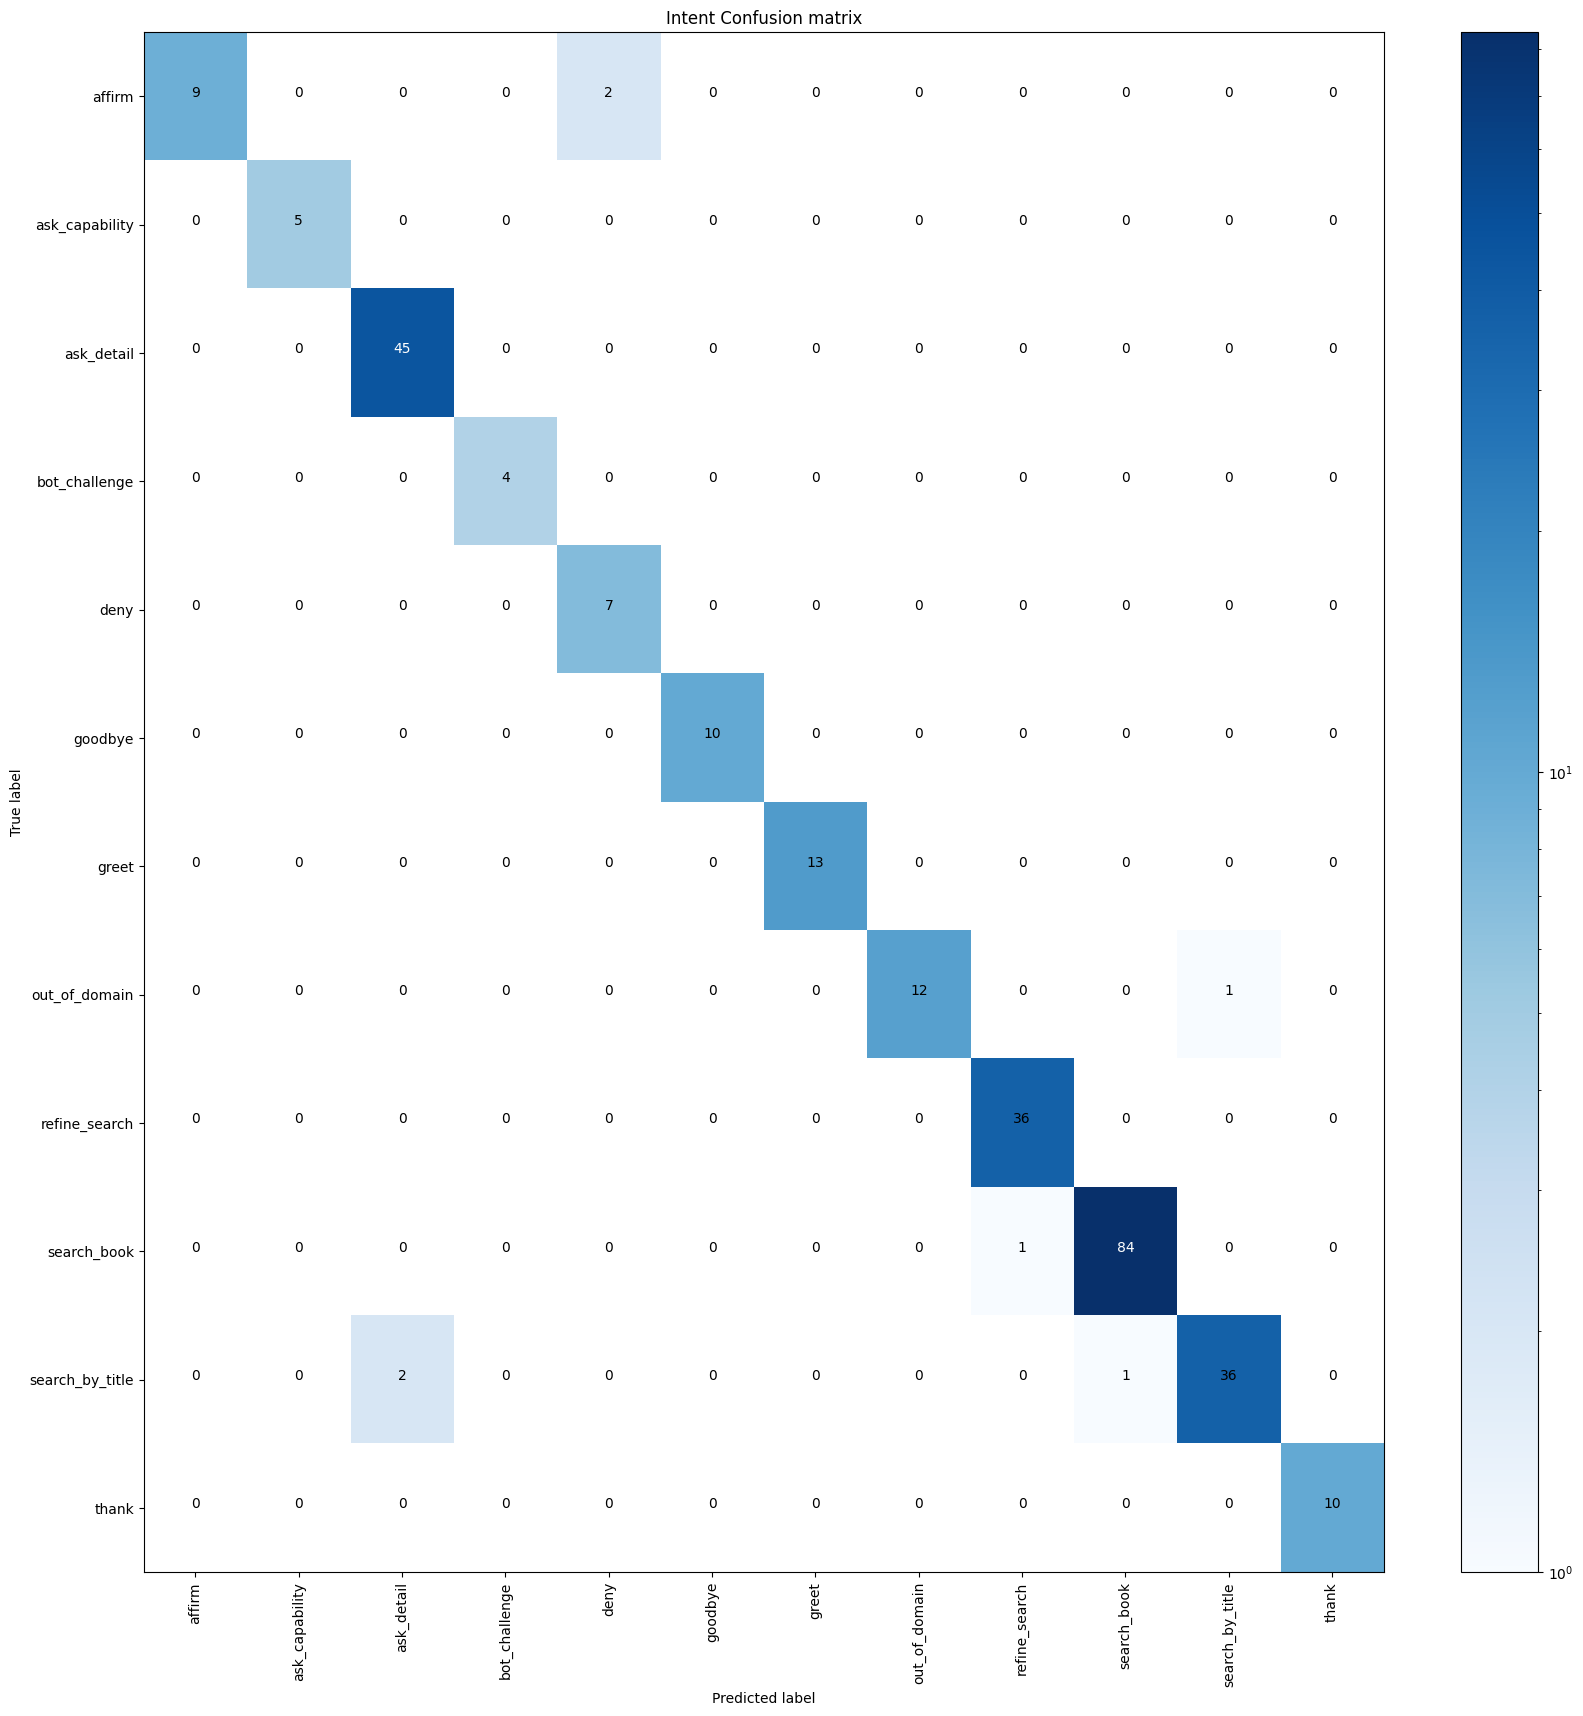

In [11]:
os.environ["MPLBACKEND"] = "Agg"      # sửa lỗi matplotlib_inline

sh([RASA, "test", "nlu", "--nlu", "train_test_split/test_data.yml", "--model", "models/eval-bot.tar.gz",
    "--out", "results/nlu_eval"], cwd=PROJ, env=rasa_env(), quiet=True)

import pandas as pd
rep = json.load(open(PROJ / "results/nlu_eval/intent_report.json", encoding="utf-8"))
print(f"INTENT  accuracy = {rep['accuracy']:.4f} | weighted F1 = {rep['weighted avg']['f1-score']:.4f} | macro F1 = {rep['macro avg']['f1-score']:.4f}")
rows = {k: v for k, v in rep.items() if isinstance(v, dict) and k not in ("macro avg", "weighted avg", "micro avg")}
display(pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]].round(3))

ent_file = PROJ / "results/nlu_eval/DIETClassifier_report.json"
if ent_file.exists():
    er = json.load(open(ent_file, encoding="utf-8"))
    print(f"\nENTITY  weighted F1 = {er['weighted avg']['f1-score']:.4f}")
    rows = {k: v for k, v in er.items() if isinstance(v, dict) and k not in ("macro avg", "weighted avg", "micro avg")}
    display(pd.DataFrame(rows).T[["precision", "recall", "f1-score", "support"]].round(3))

from IPython.display import Image
cm = PROJ / "results/nlu_eval/intent_confusion_matrix.png"
if cm.exists(): display(Image(str(cm))) 

In [12]:
# Bản cuối: huấn luyện trên TOÀN BỘ dữ liệu (dùng cho demo) + kiểm tra mô hình hội thoại bằng test stories
sh([RASA, "train", "--domain", "domain.yml", "--config", "config.yml", "--data", "data",
    "--out", "models", "--fixed-model-name", "book-bot"], cwd=PROJ, env=rasa_env())
sh([RASA, "test", "core", "--stories", "tests/test_stories.yml", "--model", "models/book-bot.tar.gz",
    "--out", "results/core"], cwd=PROJ, env=rasa_env(), check=False)
print(sorted(os.listdir(PROJ / "models")))

/tmp/rasa_env/lib/python3.10/site-packages/rasa/core/tracker_store.py:1044: MovedIn20Warning: Deprecated API features detected! These feature(s) are not compatible with SQLAlchemy 2.0. To prevent incompatible upgrades prior to updating applications, ensure requirements files are pinned to "sqlalchemy<2.0". Set environment variable SQLALCHEMY_WARN_20=1 to show all deprecation warnings.  Set environment variable SQLALCHEMY_SILENCE_UBER_WARNING=1 to silence this message. (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)
  Base: DeclarativeMeta = declarative_base()
/tmp/rasa_env/lib/python3.10/site-packages/rasa/shared/utils/validation.py:134: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources
/tmp/rasa_env/lib/python3.10/site-packages/pkg_resources/__init__.py:3117: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespace('mpl_toolkits')`.
Implementing implicit namespace p

## 7. Chạy chatbot (action server + Rasa server) và hội thoại thử
Mở 2 tiến trình nền: **action server** (cổng 5055) và **Rasa server** (cổng 5005, kênh REST). Log ở `/kaggle/working/actions.log`, `rasa.log` (xem khi có lỗi).

In [13]:
import atexit
PROCS = []

def start(cmd, log):
    p = subprocess.Popen(cmd, cwd=PROJ, env=rasa_env(), stdout=open(ROOT / log, "w"), stderr=subprocess.STDOUT)
    PROCS.append(p); return p

def stop_all():
    for p in PROCS:
        if p.poll() is None: p.terminate()
    PROCS.clear()
atexit.register(stop_all)

OPENER = urllib.request.build_opener(urllib.request.ProxyHandler({}))      # không đi qua proxy cho localhost

def wait_http(url, timeout=300):
    t0 = time.time()
    while time.time() - t0 < timeout:
        try:
            with OPENER.open(url, timeout=5) as r: return r.read().decode()[:80]
        except Exception: time.sleep(3)
    raise TimeoutError(f"Server không phản hồi: {url}. Xem log trong {ROOT}.")

MODEL_PATH = "models/book-bot.tar.gz"          # đổi nếu bạn dùng model đã train từ trước
stop_all()
start([RASA, "run", "actions", "--port", "5055"], "actions.log")
print("Action server:", wait_http("http://localhost:5055/health", 120))
start([RASA, "run", "--enable-api", "--port", "5005", "--model", MODEL_PATH,
       "--endpoints", "endpoints.yml", "--credentials", "credentials.yml"], "rasa.log")
print("Rasa server  :", wait_http("http://localhost:5005/", 300))

Action server: {"status":"ok"}
Rasa server  : Hello from Rasa: 3.6.21


In [14]:
def post(path, payload):
    req = urllib.request.Request("http://localhost:5005" + path, data=json.dumps(payload).encode("utf-8"),
                                 headers={"Content-Type": "application/json"})
    with OPENER.open(req, timeout=120) as r: return json.loads(r.read())

def parse(text):
    r = post("/model/parse", {"text": text})
    return r["intent"]["name"], round(r["intent"]["confidence"], 2), [(e["entity"], e["value"]) for e in r.get("entities", [])]

def say(msg, sender="demo", debug=True):
    if debug: print("   [NLU]", parse(msg))
    print("👤", msg)
    for m in post("/webhooks/rest/webhook", {"sender": sender, "message": msg}):
        print("🤖", m.get("text", ""))
        for b in m.get("buttons", []) or []: print("    [nút]", b["title"])
    print()

for u in ["Xin chào",
          "Gợi ý cho mình sách trinh thám",
          "Lọc thêm giúp mình đánh giá từ 4.0 sao trở lên",
          "Cuốn thứ hai giá bao nhiêu?",
          "Shop có cuốn Đắc Nhân Tâm không?",
          "goi y sach thieu nhi gia duoi 100k",        # gõ không dấu
          "Hôm nay thời tiết thế nào?",
          "Cảm ơn bạn, tạm biệt"]:
    say(u, sender="demo1")

   [NLU] ('greet', 1.0, [])
👤 Xin chào
🤖 Dạ, xin chào bạn! Mình là trợ lý tìm sách của nhà sách. Bạn muốn mình gợi ý sách thể loại nào ạ (văn học, trinh thám, thiếu nhi, truyện tranh, kinh tế, tâm lý...), hay bạn đang tìm một cuốn cụ thể?

   [NLU] ('search_book', 1.0, [('genre', 'trinh thám')])
👤 Gợi ý cho mình sách trinh thám
🤖 Dạ, mình tìm được 6 cuốn phù hợp (thể loại trinh thám). Top gợi ý:
1. Án Mạng Trên Chuyến Tàu Tốc Hành Phương Đông – Agatha Christie | 1934 | 4.7★ | 255.000đ
2. Bạch Dạ Hành – Higashino Keigo | 1999 | 4.7★ | 215.000đ
3. Và Rồi Chẳng Còn Ai – Agatha Christie | 1939 | 4.1★ | 215.000đ
4. Nghi Can X – Higashino Keigo | 2005 | 4.1★ | 240.000đ
5. Sherlock Holmes Toàn Tập – Arthur Conan Doyle | 1892 | 3.9★ | 60.000đ
Bạn muốn xem chi tiết cuốn nào, hay lọc thêm theo giá, đánh giá, năm xuất bản ạ?
    [nút] Xem chi tiết cuốn đầu tiên
    [nút] Đánh giá từ 4.5 sao
    [nút] Giá dưới 150k

   [NLU] ('refine_search', 1.0, [('rating_min', '4.0')])
👤 Lọc thêm giúp mình đánh

### Đánh giá hội thoại (task success)
Chạy các kịch bản nhiều lượt qua **server thật** và kiểm tra câu trả lời có chứa đúng sách mà kho dữ liệu trả về (so với kết quả tính trực tiếp từ `BOOKS`). Đây là chỉ số cuối cùng phản ánh cả NLU + policy + action chạy cùng nhau.

In [15]:
def expect(**f):
    rows = [b for b in BOOKS if (not f.get("genre") or b["genre"] == f["genre"]) and (not f.get("author") or b["author"] == f["author"])
            and b["rating"] >= f.get("rating_min", 0) and b["price"] <= f.get("price_max", 10**9) and b["year"] >= f.get("year_min", 0)]
    return sorted(rows, key=lambda b: (-b["rating"], b["id"]))

def top_title(**f):
    r = expect(**f); return r[0]["title"] if r else "chưa có cuốn nào"

by_title = {b["title"]: b for b in BOOKS}
r2 = expect(genre="trinh thám")
SCENARIOS = [
    ("Tìm theo thể loại", [("Gợi ý cho mình sách trinh thám", [top_title(genre="trinh thám")])]),
    ("Tìm theo tác giả", [("Tìm giúp mình sách của Nguyễn Nhật Ánh", [top_title(author="Nguyễn Nhật Ánh")])]),
    ("Thể loại + giá", [("Mình muốn tìm sách kinh tế giá dưới 150k", [top_title(genre="kinh tế", price_max=150)])]),
    ("Lọc thêm", [("Gợi ý cho mình sách tâm lý", [top_title(genre="tâm lý")]),
                  ("Lọc thêm giúp mình đánh giá từ 4.5 sao trở lên", [top_title(genre="tâm lý", rating_min=4.5)])]),
    ("Hỏi giá cuốn thứ hai", [("Gợi ý cho mình sách trinh thám", [top_title(genre="trinh thám")]),
                              ("Cuốn thứ hai giá bao nhiêu?", [f"{r2[1]['price'] * 1000:,}".replace(",", ".") + "đ"])]),
    ("Hỏi tác giả cuốn đầu", [("Cho mình xem sách truyện tranh", [top_title(genre="truyện tranh")]),
                              ("Cuốn đầu tiên ai viết?", [expect(genre="truyện tranh")[0]["author"]])]),
    ("Tìm theo tên sách", [("Shop có cuốn Đắc Nhân Tâm không?", ["Đắc Nhân Tâm", by_title["Đắc Nhân Tâm"]["author"]])]),
    ("Gõ không dấu", [("goi y sach khoa hoc vien tuong", [top_title(genre="khoa học viễn tưởng")])]),
    ("Ngoài phạm vi", [("Hôm nay thời tiết thế nào?", ["chỉ hỗ trợ tìm kiếm"])]),
]

ok = tot = 0
for i, (name, turns) in enumerate(SCENARIOS):
    sender, good = f"eval{i}", True
    for msg, must in turns:
        reply = " ".join(m.get("text", "") for m in post("/webhooks/rest/webhook", {"sender": sender, "message": msg}))
        hit = all(s.lower() in reply.lower() for s in must)
        good &= hit
        if not hit: print(f"  ✗ [{name}] '{msg}' thiếu {must}\n    -> {reply[:200]!r}")
    ok += good; tot += 1
    print(("✔" if good else "✘"), name)
print(f"\nTask success: {ok}/{tot} = {ok / tot:.0%}")

✔ Tìm theo thể loại
✔ Tìm theo tác giả
✔ Thể loại + giá
✔ Lọc thêm
✔ Hỏi giá cuốn thứ hai
✔ Hỏi tác giả cuốn đầu
✔ Tìm theo tên sách
✔ Gõ không dấu
✔ Ngoài phạm vi

Task success: 9/9 = 100%


In [22]:
# Chat tương tác (bỏ comment để dùng). Gõ 'thoát' để dừng, 'reset' để bắt đầu lại.
sid = "me"
while True:
     u = input("👤 Bạn: ").strip()
     if u.lower() in ("thoát", "quit", "exit"): break
     if u.lower() == "reset": sid = f"me{time.time()}"; continue
     say(u, sender=sid) 

👤 Bạn:  thoát


## 8. Lưu kết quả & dùng lại model
Mọi file nằm trong `/kaggle/working/book_rasa` (Kaggle tự lưu thành *Output* khi bạn bấm *Save Version*). Cell dưới nén thành 1 file zip để tải về.

**Dùng lại model đã train (không train lại):** upload file `book-bot.tar.gz` (và toàn bộ thư mục project, vì action server cần `actions/` và `data/books.json`) thành Kaggle Dataset → chạy lại **cell cài Rasa**, các cell **mục 0** (cấu hình), rồi sửa `PROJ` trỏ tới thư mục dataset (hoặc copy vào `/kaggle/working`) và `MODEL_PATH` ở mục 7, bỏ qua các cell huấn luyện.

In [18]:
stop_all()
zip_path = shutil.make_archive(str(ROOT / "book_rasa_project"), "zip", PROJ)
print("Đã nén:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")

Đã nén: /kaggle/working/book_rasa_project.zip (135.2 MB)


## 9. Gợi ý cho báo cáo (so sánh với hướng end-to-end)
| Tiêu chí | Rasa (pipeline) | T5/BART (end-to-end) |
|---|---|---|
| Kiểm soát hành vi | Cao: rules/stories/action rõ ràng, dễ debug | Thấp hơn: hành vi nằm trong trọng số |
| Dữ liệu cần | Ít (vài trăm câu có nhãn) | Nhiều hơn (hội thoại đầy đủ) |
| Độ linh hoạt câu trả lời | Theo mẫu/template | Sinh tự do hơn nhưng có thể sai |
| Lỗi dây chuyền | Có (NLU sai → action sai), giảm bằng regex dự phòng | Có (belief state sai → câu trả lời sai) |
| Triển khai | Server riêng, kênh REST/Slack/Telegram... | Chạy trực tiếp trong Python |

* Dùng chung **bộ kịch bản + thang đo task success** cho cả hai hệ thống để so sánh công bằng, và thêm **SUS** + thời gian hoàn thành nhiệm vụ với người dùng thật (môn HCI).
* Thêm câu mẫu thật (khảo sát bạn bè), tăng số đầu sách, kiểm thử với câu có lỗi chính tả để số liệu đáng tin hơn dữ liệu template.